Forme des données : (1797, 64)
Nombre d'exemples : 1797
Nombre de dimensions : 64


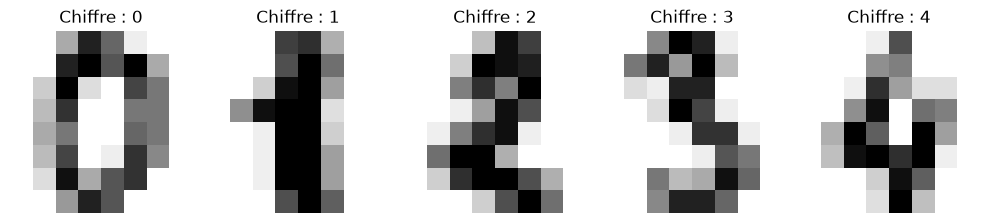

In [17]:
import matplotlib.pyplot as plt # <-- L'import manquant
from sklearn.datasets import load_digits

digits = load_digits()
X_digits = digits.data
y_digits = digits.target

print("Forme des données :", X_digits.shape)
print("Nombre d'exemples :", X_digits.shape[0])
print("Nombre de dimensions :", X_digits.shape[1])

fig, axes = plt.subplots(1, 5, figsize=(10, 3))
for ax, img, label in zip(axes, digits.images[:5], digits.target[:5]):
    ax.imshow(img, cmap='gray_r')
    ax.set_title(f"Chiffre : {label}")
    ax.axis('off')
plt.tight_layout()
plt.show()

Partie 1 – Le swiss-roll
Tâche 1 – Générer et visualiser les données

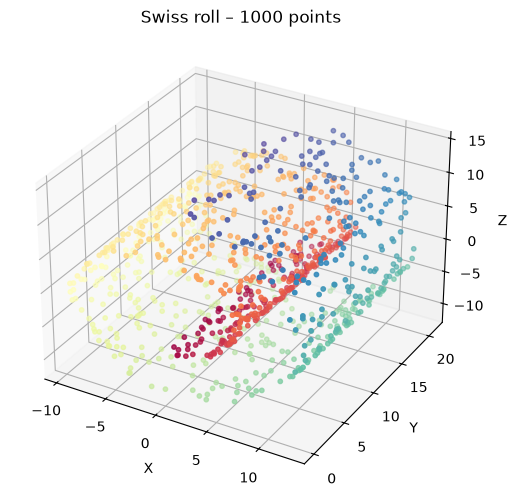

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_swiss_roll

# Génération du swiss-roll
X, t = make_swiss_roll(n_samples=1000, noise=0.05, random_state=42)

# Visualisation 3D
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=t, cmap='Spectral', s=10)
ax.set_title("Swiss roll – 1000 points")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.show()

Tâche 2 – Appliquer une méthode linéaire (PCA)


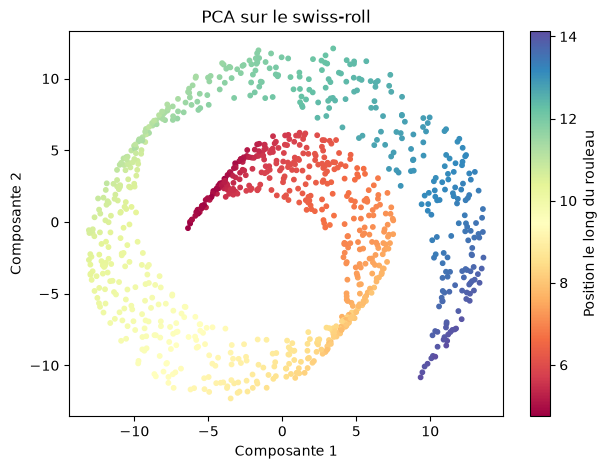

In [19]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(7, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=t, cmap='Spectral', s=10)
plt.title("PCA sur le swiss-roll")
plt.xlabel("Composante 1")
plt.ylabel("Composante 2")
plt.colorbar(label="Position le long du rouleau")
plt.show()

Tâche 3 – Isomap et LLE

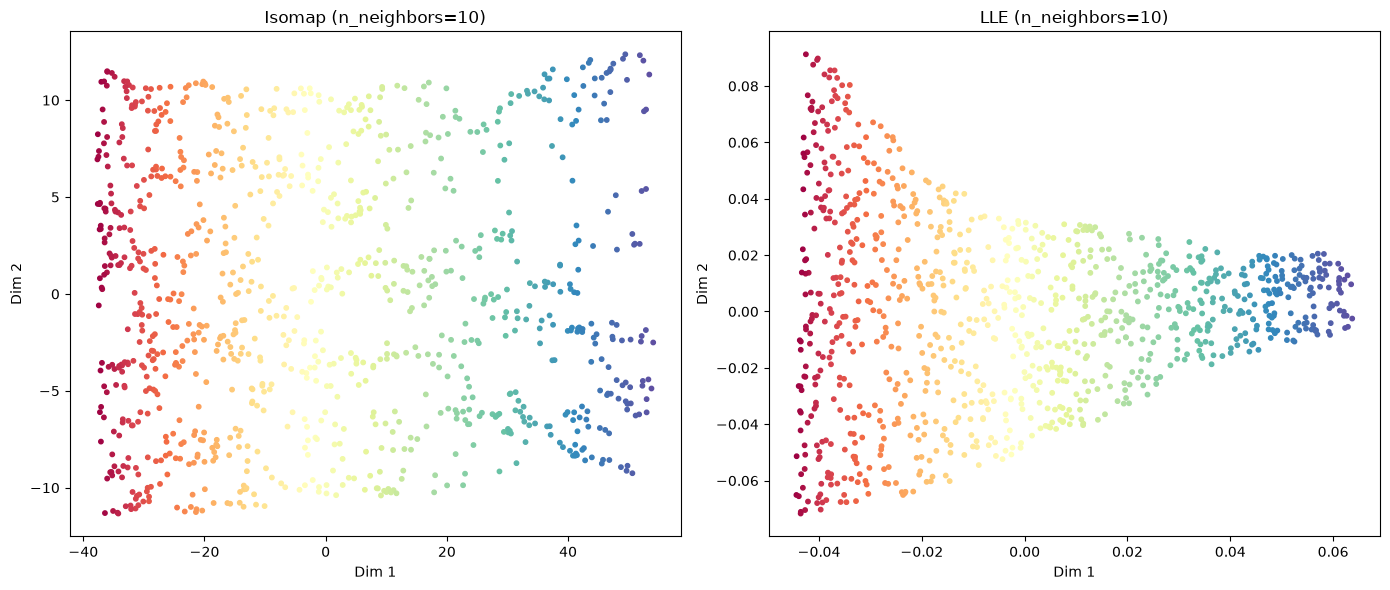

In [20]:
from sklearn.manifold import Isomap, LocallyLinearEmbedding

isomap = Isomap(n_components=2, n_neighbors=10)
X_isomap = isomap.fit_transform(X)

lle = LocallyLinearEmbedding(n_components=2, n_neighbors=10, method='standard')
X_lle = lle.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(X_isomap[:, 0], X_isomap[:, 1], c=t, cmap='Spectral', s=10)
axes[0].set_title("Isomap (n_neighbors=10)")

axes[1].scatter(X_lle[:, 0], X_lle[:, 1], c=t, cmap='Spectral', s=10)
axes[1].set_title("LLE (n_neighbors=10)")

for ax in axes:
    ax.set_xlabel("Dim 1")
    ax.set_ylabel("Dim 2")

plt.tight_layout()
plt.show()

Tâche 4 – Explorer l’hyperparamètre n_neighbors


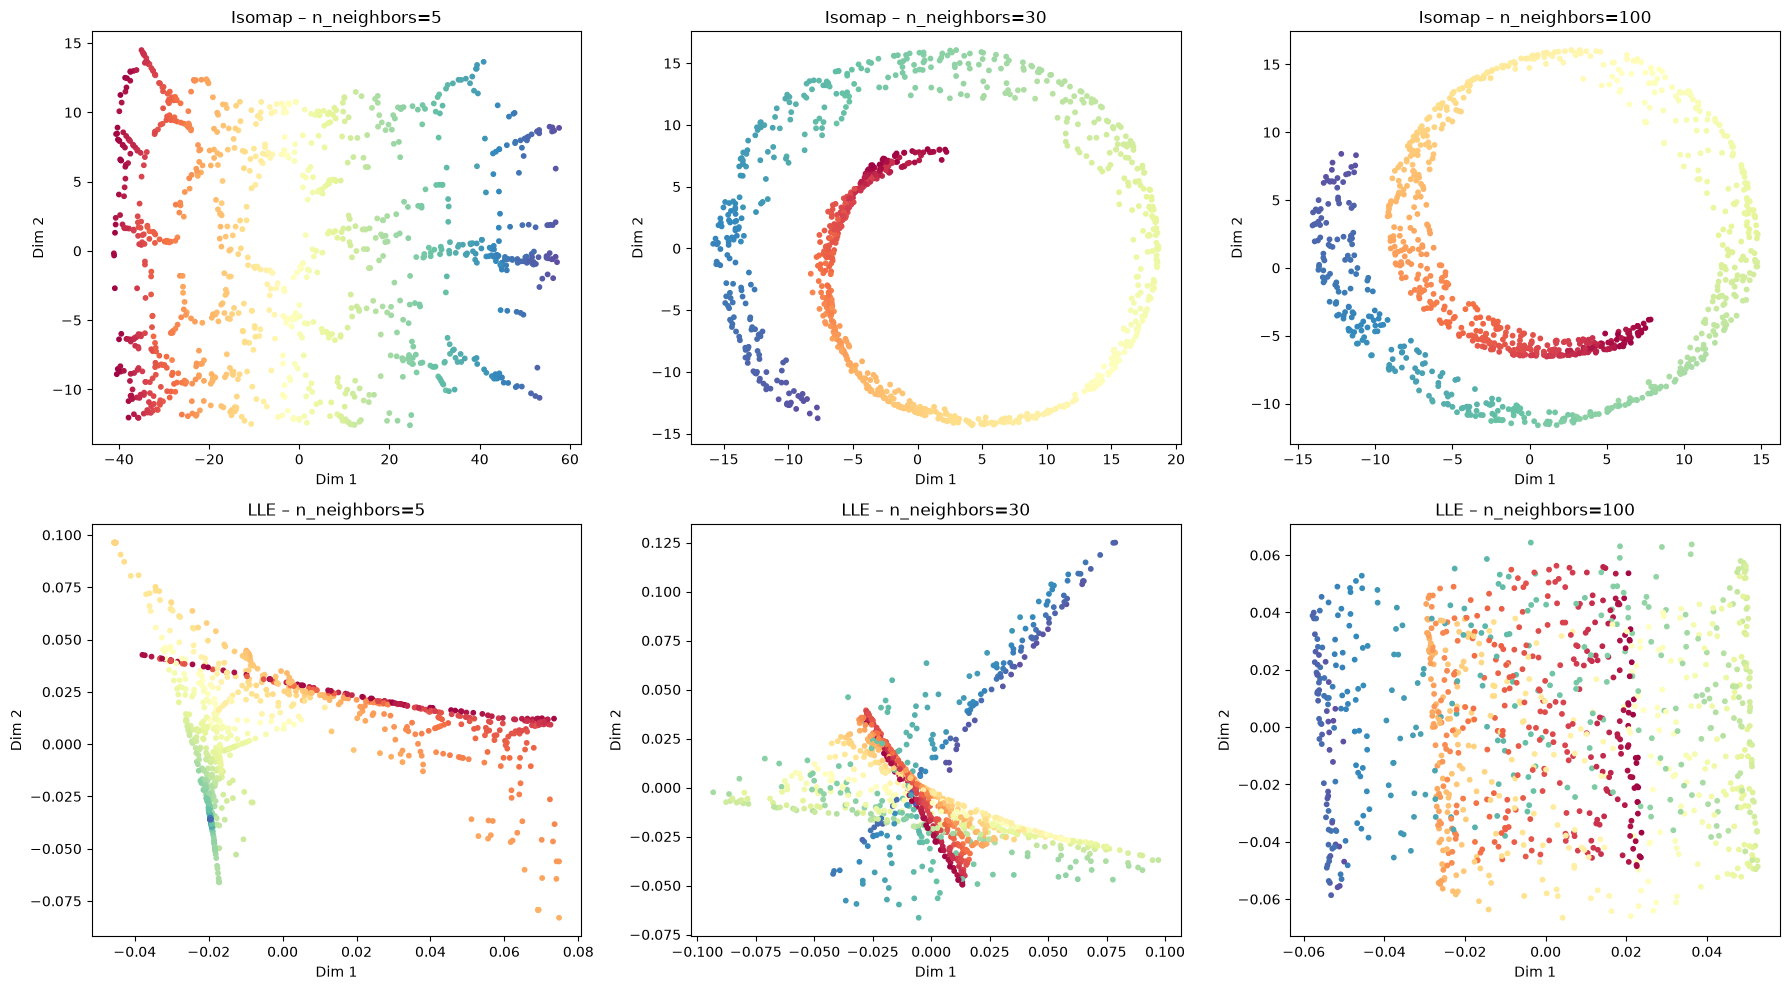

In [21]:
n_neighbors_values = [5, 30, 100]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for i, n in enumerate(n_neighbors_values):
    # Isomap
    iso = Isomap(n_components=2, n_neighbors=n)
    X_iso = iso.fit_transform(X)
    axes[0, i].scatter(X_iso[:, 0], X_iso[:, 1], c=t, cmap='Spectral', s=10)
    axes[0, i].set_title(f"Isomap – n_neighbors={n}")
    
    # LLE
    lle = LocallyLinearEmbedding(n_components=2, n_neighbors=n, method='standard')
    X_lle = lle.fit_transform(X)
    axes[1, i].scatter(X_lle[:, 0], X_lle[:, 1], c=t, cmap='Spectral', s=10)
    axes[1, i].set_title(f"LLE – n_neighbors={n}")

for ax in axes.flat:
    ax.set_xlabel("Dim 1")
    ax.set_ylabel("Dim 2")

plt.tight_layout()
plt.show()

Partie 2 – Digits : comparer les 4 algorithmes
Tâche 1 – Charger et explorer les données

Forme des données : (1797, 64)
Nombre d'exemples : 1797
Nombre de dimensions : 64


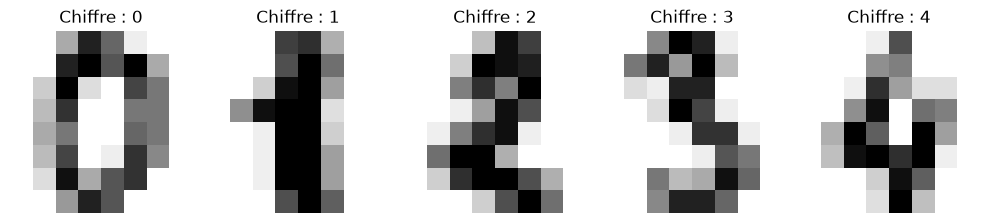

In [22]:
from sklearn.datasets import load_digits

digits = load_digits()
X_digits = digits.data
y_digits = digits.target

print("Forme des données :", X_digits.shape)
print("Nombre d'exemples :", X_digits.shape[0])
print("Nombre de dimensions :", X_digits.shape[1])

fig, axes = plt.subplots(1, 5, figsize=(10, 3))
for ax, img, label in zip(axes, digits.images[:5], digits.target[:5]):
    ax.imshow(img, cmap='gray_r')
    ax.set_title(f"Chiffre : {label}")
    ax.axis('off')
plt.tight_layout()
plt.show()

In [23]:
pip install numpy matplotlib scikit-learn umap-learn jupyter

Defaulting to user installation because normal site-packages is not writeable
  Using cached umap_learn-0.5.12-py3-none-any.whl.metadata (24 kB)
  Using cached jupyter-1.1.1-py2.py3-none-any.whl.metadata (2.0 kB)
  Using cached pynndescent-0.6.0-py3-none-any.whl.metadata (6.9 kB)
  Using cached notebook-7.6.2-py3-none-any.whl.metadata (10 kB)
  Using cached jupyter_console-6.6.3-py3-none-any.whl.metadata (5.8 kB)
  Using cached nbconvert-7.17.1-py3-none-any.whl.metadata (8.4 kB)
  Using cached ipywidgets-8.1.9-py3-none-any.whl.metadata (2.4 kB)
  Using cached jupyterlab-4.6.4-py3-none-any.whl.metadata (16 kB)
  Using cached widgetsnbextension-4.0.16-py3-none-any.whl.metadata (1.6 kB)
  Using cached jupyterlab_widgets-3.0.17-py3-none-any.whl.metadata (20 kB)
  Using cached async_lru-2.3.0-py3-none-any.whl.metadata (7.6 kB)
  Using cached jupyter_builder-1.2.3-py3-none-any.whl.metadata (7.8 kB)
  Using cached jupyter_lsp-2.3.1-py3-none-any.whl.metadata (1.8 kB)
  Using cached jupyter_ser

Tâche 2 – Comparer 4 algorithmes


/home/tawil/.local/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


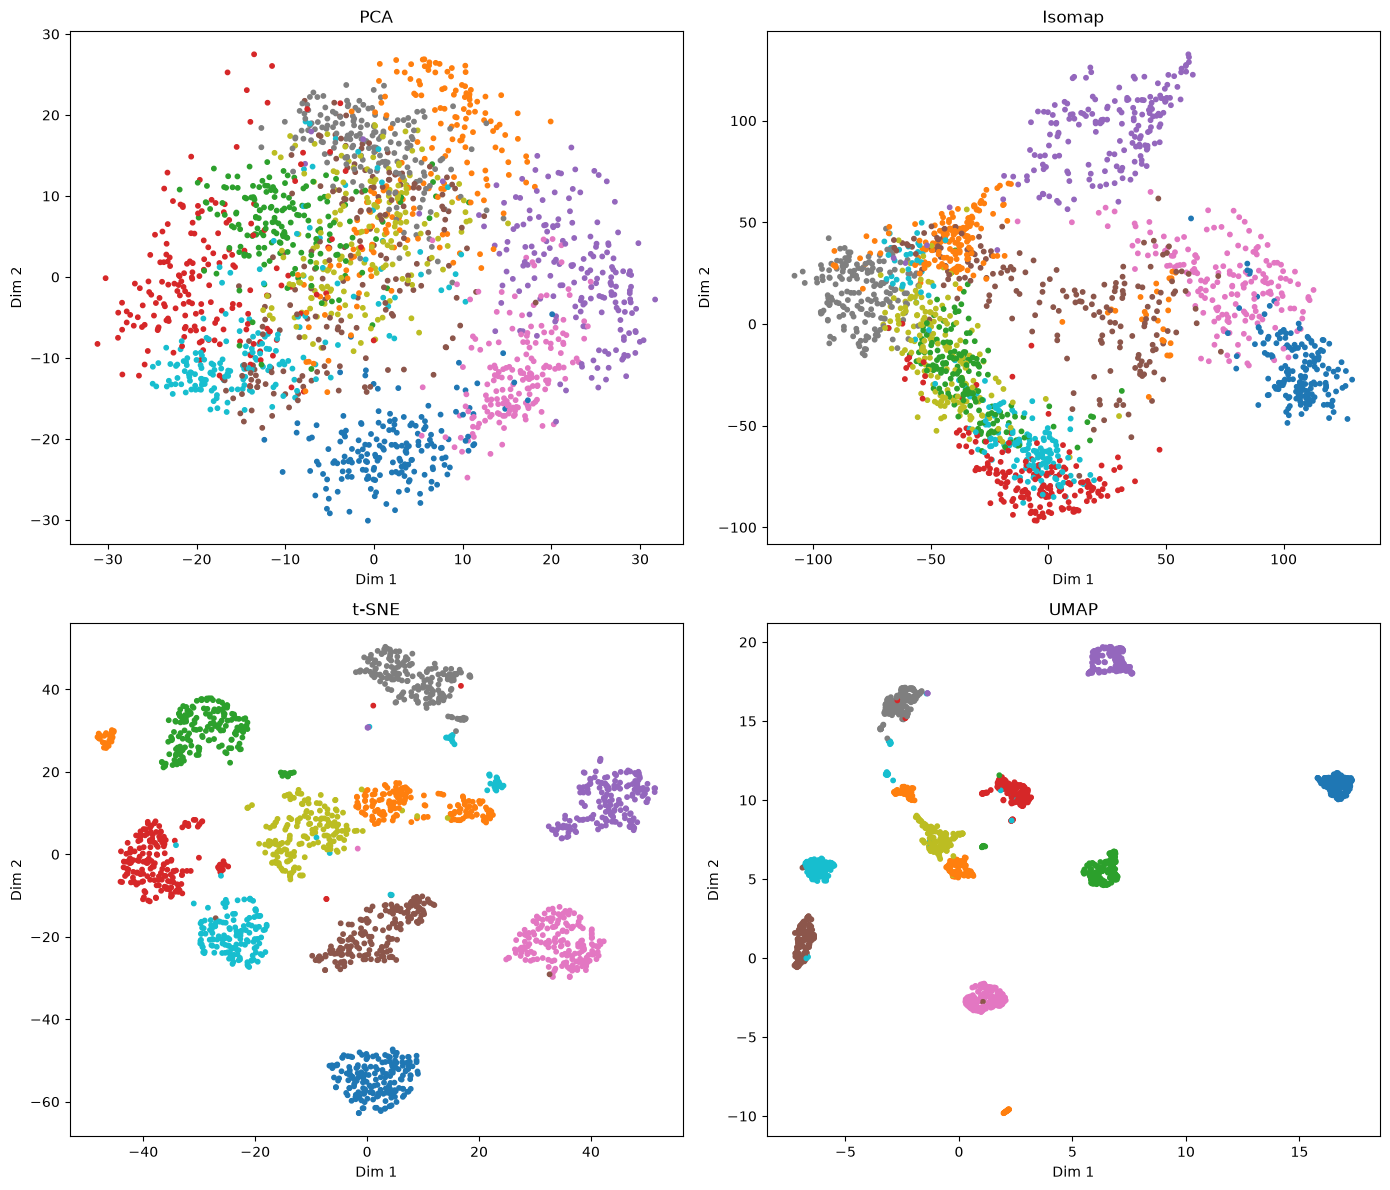

In [24]:
from sklearn.manifold import TSNE
import umap

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_digits)

# Isomap
isomap = Isomap(n_components=2, n_neighbors=10)
X_isomap = isomap.fit_transform(X_digits)

# t-SNE
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_digits)

# UMAP
umap_model = umap.UMAP(n_components=2, random_state=42)
X_umap = umap_model.fit_transform(X_digits)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
methodes = [
    ("PCA", X_pca),
    ("Isomap", X_isomap),
    ("t-SNE", X_tsne),
    ("UMAP", X_umap)
]

for ax, (nom, X_red) in zip(axes.flat, methodes):
    scatter = ax.scatter(X_red[:, 0], X_red[:, 1], c=y_digits, cmap='tab10', s=10)
    ax.set_title(nom)
    ax.set_xlabel("Dim 1")
    ax.set_ylabel("Dim 2")

plt.tight_layout()
plt.show()

Tâche 3 – Effet de la perplexité et temps d’exécution


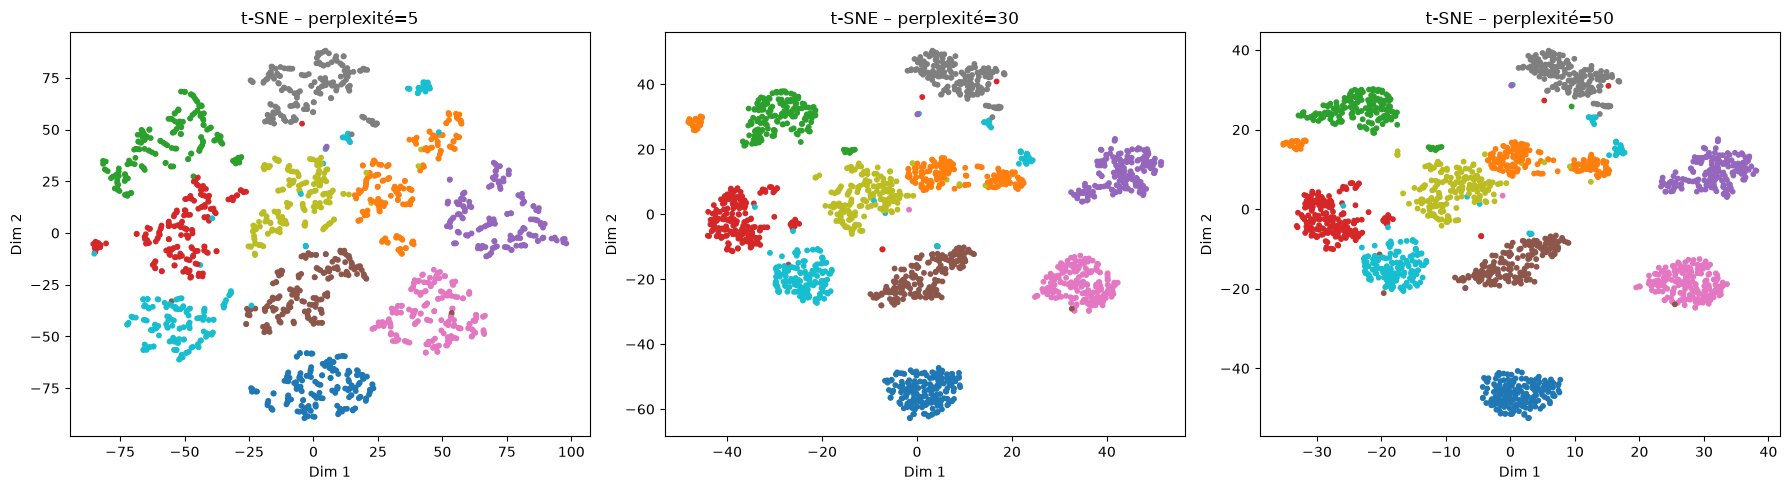

/home/tawil/.local/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


PCA      : 0.007 s
Isomap   : 0.621 s
t-SNE    : 2.837 s
UMAP     : 3.518 s


In [25]:
import time

perplexities = [5, 30, 50]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, perp in zip(axes, perplexities):
    tsne = TSNE(n_components=2, perplexity=perp, random_state=42)
    X_tsne = tsne.fit_transform(X_digits)
    ax.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_digits, cmap='tab10', s=10)
    ax.set_title(f"t-SNE – perplexité={perp}")
    ax.set_xlabel("Dim 1")
    ax.set_ylabel("Dim 2")
plt.tight_layout()
plt.show()

# Mesure des temps
def time_method(method, X):
    start = time.perf_counter()
    method.fit_transform(X)
    end = time.perf_counter()
    return end - start

temps = {}
temps['PCA'] = time_method(PCA(n_components=2), X_digits)
temps['Isomap'] = time_method(Isomap(n_components=2, n_neighbors=10), X_digits)
temps['t-SNE'] = time_method(TSNE(n_components=2, perplexity=30, random_state=42), X_digits)
temps['UMAP'] = time_method(umap.UMAP(n_components=2, random_state=42), X_digits)

for nom, t in temps.items():
    print(f"{nom:8s} : {t:.3f} s")

Classement de la moins bonne à la meilleure séparation visuelle :
PCA < Isomap < UMAP ≈ t-SNE.

PCA est linéaire et ne capture pas les variations non linéaires des chiffres.

Isomap améliore mais peut être sensible aux voisinages.

t-SNE et UMAP forment des amas bien séparés par chiffre, car ils préservent les voisinages locaux.

Pourquoi PCA sépare moins bien : les images de chiffres varient de façon non linéaire (rotation, épaisseur, style d’écriture). PCA cherche des directions linéaires de variance maximale, ce qui ne suffit pas à démêler ces variations.

Effet de la perplexité pour t-SNE :

Trop faible (ex. 5) : t-SNE se concentre sur des voisinages très locaux, crée de petits amas fragmentés, perd la structure globale.

Trop élevée (ex. 50) : t-SNE lisse trop, peut fusionner des classes ou mal séparer les groupes.

Une valeur intermédiaire (souvent 30) donne un bon compromis.

Méthode la plus rapide / la plus lente :

La plus rapide : PCA (algèbre linéaire, SVD).

La plus lente : généralement t-SNE, surtout avec beaucoup de points.

UMAP est souvent plus rapide que t-SNE et scalable.
Cela est cohérent avec le cours : les méthodes linéaires sont rapides, les méthodes non linéaires locales sont plus coûteuses, t-SNE est optimisé pour la visualisation mais lent sur de grands jeux.

Partie 3 – Un premier pas vers le médical
Tâche 1 – Charger et explorer les données

In [26]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()
X_cancer = cancer.data
y_cancer = cancer.target

print("Nombre de patients :", X_cancer.shape[0])
print("Nombre de caractéristiques :", X_cancer.shape[1])
print("Classes :", cancer.target_names)

Nombre de patients : 569
Nombre de caractéristiques : 30
Classes : ['malignant' 'benign']


Tâche 2 – Préparer et projeter avec UMAP


/home/tawil/.local/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


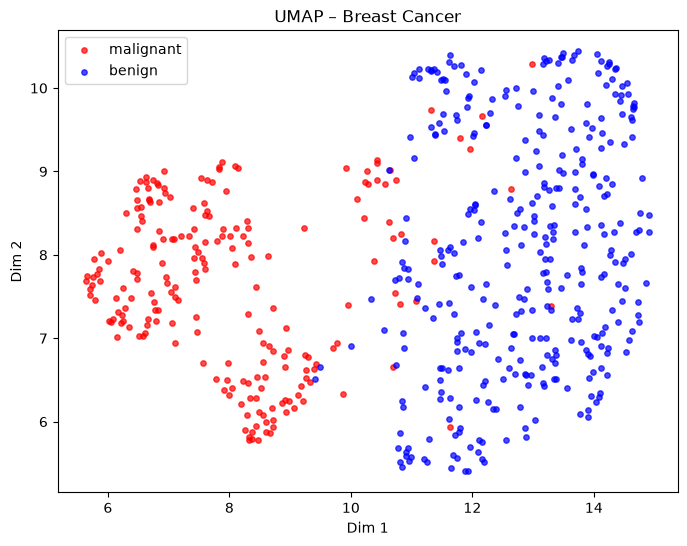

In [27]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_cancer_scaled = scaler.fit_transform(X_cancer)

umap_cancer = umap.UMAP(n_components=2, random_state=42)
X_cancer_umap = umap_cancer.fit_transform(X_cancer_scaled)

plt.figure(figsize=(8, 6))
for classe, couleur, label in zip([0, 1], ['red', 'blue'], cancer.target_names):
    plt.scatter(X_cancer_umap[y_cancer == classe, 0],
                X_cancer_umap[y_cancer == classe, 1],
                c=couleur, label=label, s=15, alpha=0.7)
plt.title("UMAP – Breast Cancer")
plt.xlabel("Dim 1")
plt.ylabel("Dim 2")
plt.legend()
plt.show()

Tâche 3 – Comparer avec PCA


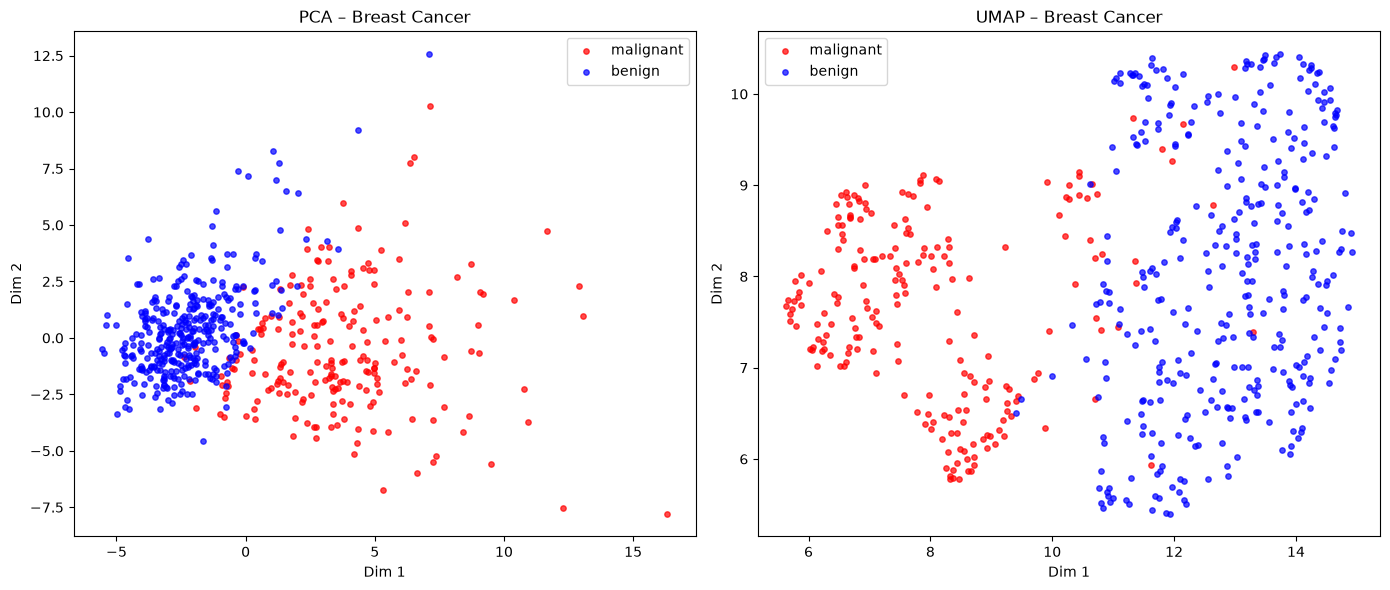

In [28]:
pca_cancer = PCA(n_components=2)
X_cancer_pca = pca_cancer.fit_transform(X_cancer_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for classe, couleur, label in zip([0, 1], ['red', 'blue'], cancer.target_names):
    axes[0].scatter(X_cancer_pca[y_cancer == classe, 0],
                    X_cancer_pca[y_cancer == classe, 1],
                    c=couleur, label=label, s=15, alpha=0.7)
    axes[1].scatter(X_cancer_umap[y_cancer == classe, 0],
                    X_cancer_umap[y_cancer == classe, 1],
                    c=couleur, label=label, s=15, alpha=0.7)

axes[0].set_title("PCA – Breast Cancer")
axes[1].set_title("UMAP – Breast Cancer")
for ax in axes:
    ax.set_xlabel("Dim 1")
    ax.set_ylabel("Dim 2")
    ax.legend()

plt.tight_layout()
plt.show()

Séparation bénin/malin avec UMAP : oui, UMAP sépare généralement bien les deux classes, avec deux groupes distincts, même s’il peut rester quelques points proches de la frontière.

PCA fait-il aussi bien ? PCA peut donner une séparation correcte car les tumeurs malignes et bénignes diffèrent sur de nombreuses caractéristiques. Cependant, UMAP capture mieux les relations non linéaires et produit souvent des groupes plus nets. PCA reste une bonne baseline linéaire.

Pourquoi standardiser avant UMAP : UMAP utilise des distances entre points. Si les variables ont des échelles très différentes, celles avec les plus grandes valeurs dominent le calcul des distances. La standardisation met toutes les variables à la même échelle (moyenne 0, écart-type 1), ce qui est indispensable.

Lien avec le point cloud pulmonaire : dans les deux cas, on a des données médicales de grande dimension qui reposent probablement sur une variété de faible dimension. Le Manifold Learning permet de visualiser et d’explorer la structure des données (par ex. distinguer des pathologies) avant d’appliquer des algorithmes de diagnostic ou de segmentation.

Partie 4 – Discussion
1.Hypothèse de la variété : un jeu de données à 30 caractéristiques peut se projeter en 2D si les observations ne remplissent pas tout l’espace 30D mais se concentrent près d’une variété de dimension 2. Autrement dit, les 30 variables sont contrôlées par quelques facteurs latents (taille, texture, forme…). Breast Cancer est un bon exemple : les classes bénin/malin se structurent autour de quelques axes principaux.

2.Pour un très grand jeu (millions de points) :

Si l’objectif est la vitesse pure et une structure globalement linéaire : PCA (ou Randomized PCA).

Si l’on veut capturer des structures non linéaires tout en restant scalable : UMAP. UMAP utilise des voisinages approximatifs et est beaucoup plus rapide que t-SNE sur de grands volumes.

t-SNE serait trop lent. Isomap/LLE ne passent pas à l’échelle à cause du calcul des distances géodésiques ou des reconstructions locales.

3.Intérêt de tester plusieurs algorithmes :

Aucun algorithme n’est universellement meilleur.

Chaque méthode a ses hypothèses (linéaire, locale, globale, probabiliste).

Comparer permet de vérifier la robustesse des structures observées, d’éviter les artefacts et de mieux comprendre les données.

En pratique, on combine souvent une méthode rapide (PCA) pour un premier survol, puis UMAP/t-SNE pour affiner la visualisation.

MOHAMED ETTAOUIL 2IA